1



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read files
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print(train.head())

Train shape: (10050, 25)
Test shape: (3203, 24)
       ID  Tank Failure Pressure (bar)  Liquid Ratio (%)  Tank Width (m)  \
0  3203.0                         7.32              0.42            2.42   
1  3204.0                         7.18              0.42            2.39   
2  3205.0                         7.32              0.41            2.39   
3  3206.0                         7.26              0.42            2.40   
4  3207.0                         7.32              0.42            2.40   

   Tank Length (m)  Tank Height (m)  BLEVE Height (m)  Vapour Height (m)  \
0             5.39             1.00              1.79               0.60   
1             5.39             1.01              1.81               0.59   
2             5.38             1.00              1.78               0.62   
3             5.41             1.00              1.81               0.61   
4             5.41             1.02              1.79               0.62   

   Vapour Temperature (K)  Liquid Temp

1.1 Identifying and Handling Missing Values


In [2]:
# Check missing values in train
print(train.isnull().sum())

# Check missing values in test
print(test.isnull().sum())

ID                                  5
Tank Failure Pressure (bar)         7
Liquid Ratio (%)                    9
Tank Width (m)                      9
Tank Length (m)                     9
Tank Height (m)                     8
BLEVE Height (m)                   10
Vapour Height (m)                   9
Vapour Temperature (K)             28
Liquid Temperature (K)             27
Obstacle Distance to BLEVE (m)      8
Obstacle Width (m)                  6
Obstacle Height (m)                 6
Obstacle Thickness (m)              7
Obstacle Angle                      8
Status                              7
Liquid Critical Pressure (bar)     30
Liquid Boiling Temperature (K)     29
Liquid Critical Temperature (K)    30
Sensor ID                           8
Sensor Position Side                8
Sensor Position x                   7
Sensor Position y                   8
Sensor Position z                   9
Target Pressure (bar)              10
dtype: int64
ID                                 0


Feature Selection: Remove id


In [3]:
train = train.drop('ID', axis=1)
test = test.drop('ID', axis=1)

Remove line without target presure

In [4]:
initial_len = len(train)
train = train.dropna(subset=['Target Pressure (bar)'])
print(f"Removed {initial_len - len(train)} rows due to missing target.")

Removed 10 rows due to missing target.


Add missing value

In [5]:
categorical_cols = ['Status', 'Sensor Position Side']
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove('Target Pressure (bar)')

In [6]:
from sklearn.impute import SimpleImputer

imputer_num = SimpleImputer(strategy='median')
train[numeric_cols] = imputer_num.fit_transform(train[numeric_cols])
test[numeric_cols] = imputer_num.transform(test[numeric_cols])

In [7]:
imputer_cat = SimpleImputer(strategy='most_frequent')
train[categorical_cols] = imputer_cat.fit_transform(train[categorical_cols])
test[categorical_cols] = imputer_cat.transform(test[categorical_cols])

In [8]:
print("Missing in train:", train.isnull().sum().sum())
print("Missing in test:", test.isnull().sum().sum())

Missing in train: 0
Missing in test: 0


remove duplicate

In [9]:
initial_len = len(train)
train = train.drop_duplicates()
print(f"Removed {initial_len - len(train)} duplicate rows in train.")

Removed 50 duplicate rows in train.


outliner

In [10]:
numeric_cols = [col for col in train.columns if col != 'Target Pressure (bar)' and train[col].dtype in ['float64', 'int64']]

In [11]:
outlier_limits = {}

for col in numeric_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_limits[col] = (lower, upper)

    # Capping on train
    train[col] = train[col].clip(lower, upper)

    # Capping on test
    test[col] = test[col].clip(lower, upper)

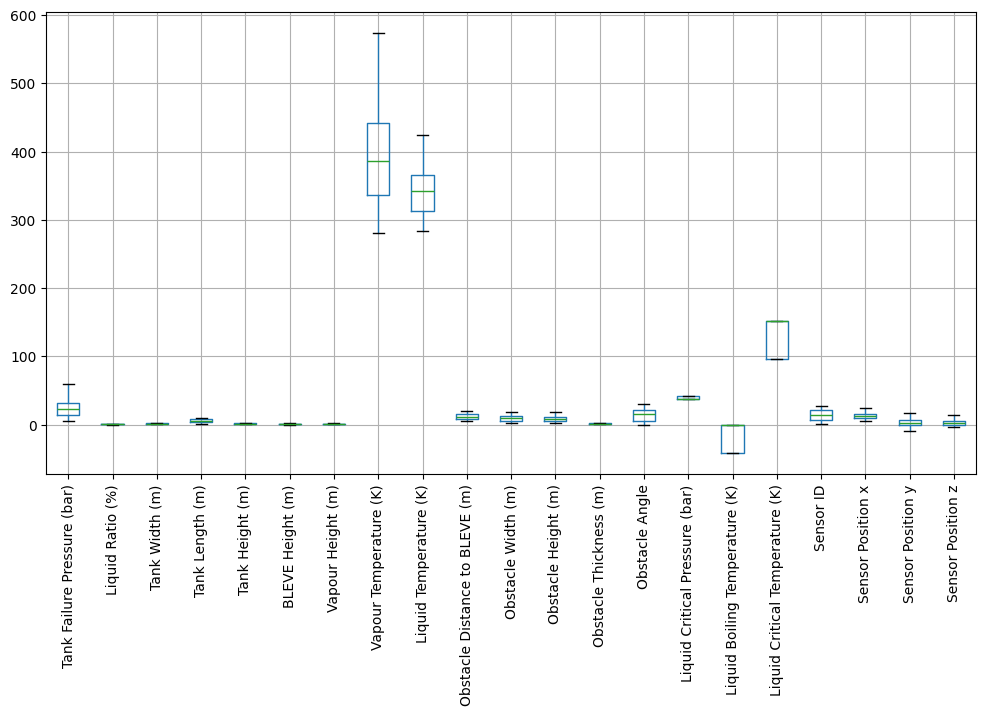

In [12]:
# Draw boxplot for visual inspection
plt.figure(figsize=(12,6))
train[numeric_cols].boxplot(rot=90)
plt.show()

 Correcting Inaccurate Entries

In [13]:
def check_bounds(df, bounds, sample_limit=5):
    # Check if values in df are within the given [min, max] range.

    violations = {}
    for col, (low, high) in bounds.items():
        if col not in df.columns:
            continue
        below = df[col] < low
        above = df[col] > high
        n_below = below.sum()
        n_above = above.sum()
        if n_below > 0 or n_above > 0:
            violations[col] = (n_below, n_above)
            print(f"\n Column '{col}':")
            print(f"   - {n_below} values < {low}")
            print(f"   - {n_above} values > {high}")
            # Get a few examples
            if n_below > 0:
                examples = df.loc[below, col].head(sample_limit).tolist()
                print(f"   - Examples of small values: {examples}")
            if n_above > 0:
                examples = df.loc[above, col].head(sample_limit).tolist()
                print(f"   - Examples of large values: {examples}")
    if not violations:
        print("All columns are within the allowed threshold range.")
    return violations

In [14]:
# Define reasonable thresholds
bounds = {
    'Tank Failure Pressure (bar)': (0, 500),
    'Liquid Ratio (%)': (0, 1),
    'Tank Width (m)': (0.1, 20),
    'Tank Length (m)': (0.1, 20),
    'Tank Height (m)': (0.1, 20),
    'BLEVE Height (m)': (0, 10),
    'Vapour Height (m)': (0, 10),
    'Vapour Temperature (K)': (0, 2000),
    'Liquid Temperature (K)': (0, 2000),
    'Obstacle Distance to BLEVE (m)': (0, 100),
    'Obstacle Width (m)': (0, 50),
    'Obstacle Height (m)': (0, 50),
    'Obstacle Thickness (m)': (0, 10),
    'Obstacle Angle': (-180, 360),
    'Liquid Critical Pressure (bar)': (0, 500),
    'Liquid Boiling Temperature (K)': (-42, -1),
    'Liquid Critical Temperature (K)': (0, 1000),
    'Sensor ID': (1, 27),
    'Sensor Position Side': (1, 5),
    'Sensor Position x': (-20, 20),
    'Sensor Position y': (-20, 20),
    'Sensor Position z': (-20, 20),
}

print("=== TRAIN SET ===")
check_bounds(train, bounds)

print("\n=== TEST SET ===")
check_bounds(test, bounds)

=== TRAIN SET ===

 Column 'BLEVE Height (m)':
   - 191 values < 0
   - 0 values > 10
   - Examples of small values: [-0.01, -0.01, -0.02, -0.01, -0.02]

 Column 'Sensor Position x':
   - 0 values < -20
   - 422 values > 20
   - Examples of large values: [20.05, 20.05, 20.05, 20.05, 20.05]

=== TEST SET ===

 Column 'Sensor Position x':
   - 0 values < -20
   - 189 values > 20
   - Examples of large values: [21.35, 21.35, 21.35, 21.35, 21.35]


{'Sensor Position x': (np.int64(0), np.int64(189))}

In [15]:
train.loc[train['BLEVE Height (m)'] < 0, 'BLEVE Height (m)'] = 0
test.loc[test['BLEVE Height (m)'] < 0, 'BLEVE Height (m)'] = 0

In [16]:
print("=== TRAIN SET (after correction) ===")
check_bounds(train, bounds)

print("\n=== TEST SET (after correction) ===")
check_bounds(test, bounds)

=== TRAIN SET (after correction) ===

 Column 'Sensor Position x':
   - 0 values < -20
   - 422 values > 20
   - Examples of large values: [20.05, 20.05, 20.05, 20.05, 20.05]

=== TEST SET (after correction) ===

 Column 'Sensor Position x':
   - 0 values < -20
   - 189 values > 20
   - Examples of large values: [21.35, 21.35, 21.35, 21.35, 21.35]


{'Sensor Position x': (np.int64(0), np.int64(189))}

Feature engineer

In [17]:
# Width/length ratio
train['Tank_WH_ratio'] = train['Tank Width (m)'] / train['Tank Length (m)']
test['Tank_WH_ratio'] = test['Tank Width (m)'] / test['Tank Length (m)']

# Vapour height / tank height ratio
train['Vapor_Height_ratio'] = train['Vapour Height (m)'] / train['Tank Height (m)']
test['Vapor_Height_ratio'] = test['Vapour Height (m)'] / test['Tank Height (m)']

# Obstacle area
train['Obstacle_Area'] = train['Obstacle Width (m)'] * train['Obstacle Height (m)']
test['Obstacle_Area'] = test['Obstacle Width (m)'] * test['Obstacle Height (m)']

# Relative distance
train['Rel_Distance'] = train['Obstacle Distance to BLEVE (m)'] / (train['Tank Width (m)'] + train['Tank Length (m)'])
test['Rel_Distance'] = test['Obstacle Distance to BLEVE (m)'] / (test['Tank Width (m)'] + test['Tank Length (m)'])

# Temperature difference
train['Temp_Diff'] = train['Vapour Temperature (K)'] - train['Liquid Temperature (K)']
test['Temp_Diff'] = test['Vapour Temperature (K)'] - test['Liquid Temperature (K)']


Data type conversion (Categorical Encoding)

In [18]:
print("Before standardization:")
print(train['Status'].value_counts())
print(test['Status'].value_counts())

Before standardization:
Status
Subcooled      6252
Superheated    3663
Subcool          23
subcooled        20
Subcoled         14
Superheat         8
superheated       6
Saperheated       4
Name: count, dtype: int64
Status
Subcooled      1890
Superheated    1313
Name: count, dtype: int64


In [19]:
def standardize_status(value):
    v = str(value).strip().lower()
    if 'super' in v or 'saper' in v:
        return 'Superheated'
    elif 'sub' in v:
        return 'Subcooled'
    else:
        return value

train['Status'] = train['Status'].apply(standardize_status)
test['Status'] = test['Status'].apply(standardize_status)

In [20]:
train = pd.get_dummies(train, columns=['Status', 'Sensor Position Side'],
                       prefix=['Status', 'Side'], drop_first=True)
test = pd.get_dummies(test, columns=['Status', 'Sensor Position Side'],
                      prefix=['Status', 'Side'], drop_first=True)

In [21]:
# Get the list of feature columns from train
feature_cols = [col for col in train.columns if col != 'Target Pressure (bar)']

# Add missing columns to test (fill with 0)
for col in feature_cols:
    if col not in test.columns:
        test[col] = 0

# Reorder test columns to match train
test = test[feature_cols]


In [22]:
print("Train columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())
assert set(train.columns) - {'Target Pressure (bar)'} == set(test.columns)

Train columns: ['Tank Failure Pressure (bar)', 'Liquid Ratio (%)', 'Tank Width (m)', 'Tank Length (m)', 'Tank Height (m)', 'BLEVE Height (m)', 'Vapour Height (m)', 'Vapour Temperature (K)', 'Liquid Temperature (K)', 'Obstacle Distance to BLEVE (m)', 'Obstacle Width (m)', 'Obstacle Height (m)', 'Obstacle Thickness (m)', 'Obstacle Angle', 'Liquid Critical Pressure (bar)', 'Liquid Boiling Temperature (K)', 'Liquid Critical Temperature (K)', 'Sensor ID', 'Sensor Position x', 'Sensor Position y', 'Sensor Position z', 'Target Pressure (bar)', 'Tank_WH_ratio', 'Vapor_Height_ratio', 'Obstacle_Area', 'Rel_Distance', 'Temp_Diff', 'Status_Superheated', 'Side_2.0', 'Side_3.0', 'Side_4.0', 'Side_5.0']
Test columns: ['Tank Failure Pressure (bar)', 'Liquid Ratio (%)', 'Tank Width (m)', 'Tank Length (m)', 'Tank Height (m)', 'BLEVE Height (m)', 'Vapour Height (m)', 'Vapour Temperature (K)', 'Liquid Temperature (K)', 'Obstacle Distance to BLEVE (m)', 'Obstacle Width (m)', 'Obstacle Height (m)', 'Obstacl

Feature Selection

In [ ]:
corr = train.corr()['Target Pressure (bar)'].abs().sort_values(ascending=False)
print(corr)
# Select features with correlation > 0.05
selected = corr[corr > 0.05].index.tolist()
if 'Target Pressure (bar)' in selected:
    selected.remove('Target Pressure (bar)')
print(f"Number of selected features: {len(selected)}")
# If selected, keep these columns
X_train = train[selected]
X_test = test[selected]

Target Pressure (bar)              1.000000
Side_2.0                           0.493143
Sensor Position x                  0.280849
Vapour Height (m)                  0.270646
Rel_Distance                       0.224464
Obstacle Distance to BLEVE (m)     0.205667
Tank Height (m)                    0.196960
Sensor Position z                  0.195522
Sensor Position y                  0.189507
Tank Length (m)                    0.164331
Obstacle_Area                      0.153503
Liquid Ratio (%)                   0.138844
Vapor_Height_ratio                 0.134244
Side_5.0                           0.127621
Obstacle Height (m)                0.113678
Side_4.0                           0.110931
Tank_WH_ratio                      0.082969
Obstacle Width (m)                 0.068923
Liquid Temperature (K)             0.064737
Sensor ID                          0.064545
Tank Failure Pressure (bar)        0.063922
BLEVE Height (m)                   0.060176
Tank Width (m)                  

Feature Scaling


In [ ]:
from sklearn.preprocessing import StandardScaler

X_train = train[selected]
y_train = train['Target Pressure (bar)']
X_test = test[selected]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Cross-validation

In [25]:
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_percentage_error, r2_score

# Create a shared cv object for all models
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print(" Created shared cross-validation (10-fold).")

 Created shared cross-validation (10-fold).


linear

In [26]:
# Check if y_train contains negative values
print("Number of negative target samples in train:", (y_train < 0).sum())
print("Min target:", y_train.min())

Number of negative target samples in train: 0
Min target: 0.016098388


In [ ]:

def compute_cost_vectorized(X, y, w, b):
    """
    X: numpy array shape (n, d)
    y: numpy array shape (n,)
    w: numpy array shape (d,)
    b: float
    """
    n = X.shape[0]
    predictions = X @ w + b  
    errors = predictions - y
    cost = (1 / (2 * n)) * np.sum(errors ** 2)
    return cost

In [28]:
def compute_gradient_vectorized(X, y, w, b):
    n = X.shape[0]
    predictions = X @ w + b
    errors = predictions - y
    dj_dw = (1 / n) * X.T @ errors
    dj_db = (1 / n) * np.sum(errors)
    return dj_dw, dj_db

In [29]:
def gradient_descent_vectorized(X, y, w_init, b_init, alpha, num_iters):
    w = w_init.copy()
    b = b_init
    cost_history = []
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_vectorized(X, y, w, b)
        w -= alpha * dj_dw
        b -= alpha * dj_db
        if i % 100 == 0:
            cost = compute_cost_vectorized(X, y, w, b)
            cost_history.append(cost)
            print(f"Iter {i}: cost = {cost:.6f}")
    return w, b, cost_history

In [30]:
# Get IDs from the original test file
original_test = pd.read_csv('test.csv')
test_ids = original_test['ID']

In [31]:
# Assuming X_train_scaled and y_train are available
X = X_train_scaled
y = y_train


w_init = np.zeros(X.shape[1])
b_init = 0.0
alpha = 0.01
iterations = 2000

# Run gradient descent
w, b, costs = gradient_descent_vectorized(X, y, w_init, b_init, alpha, iterations)

# Predict on test set (X_test_scaled)
y_pred = X_test_scaled @ w + b

# Export file
submission = pd.DataFrame({'ID': test_ids, 'Target Pressure (bar)': y_pred})
submission.to_csv('prediction.csv', index=False)

Iter 0: cost = 0.184176
Iter 100: cost = 0.075732
Iter 200: cost = 0.063080
Iter 300: cost = 0.060982
Iter 400: cost = 0.060520
Iter 500: cost = 0.060366
Iter 600: cost = 0.060290
Iter 700: cost = 0.060241
Iter 800: cost = 0.060206
Iter 900: cost = 0.060178
Iter 1000: cost = 0.060156
Iter 1100: cost = 0.060138
Iter 1200: cost = 0.060124
Iter 1300: cost = 0.060112
Iter 1400: cost = 0.060101
Iter 1500: cost = 0.060093
Iter 1600: cost = 0.060085
Iter 1700: cost = 0.060079
Iter 1800: cost = 0.060074
Iter 1900: cost = 0.060069


In [32]:
# Cell to check if prediction.csv has negative values
pred_df = pd.read_csv('prediction.csv')

# Count the number of negative values in 'Target Pressure (bar)' column
negative_count = (pred_df['Target Pressure (bar)'] < 0).sum()

print(f"Number of negative values in prediction file: {negative_count}")

if negative_count > 0:
    print("\nSome rows with negative values (max 10 rows):")
    negative_rows = pred_df[pred_df['Target Pressure (bar)'] < 0].head(10)
    print(negative_rows.to_string(index=False))

    # Statistics of negative values
    neg_values = pred_df[pred_df['Target Pressure (bar)'] < 0]['Target Pressure (bar)']
    print(f"\nMin: {neg_values.min()}")
    print(f"Max: {neg_values.max()}")
    print(f"Mean of negative values: {neg_values.mean():.6f}")
else:
    print("No negative values found.")

Number of negative values in prediction file: 687

Some rows with negative values (max 10 rows):
 ID  Target Pressure (bar)
 28              -0.068560
 29              -0.196255
 30              -0.035746
 31              -0.163441
 32              -0.291136
 33              -0.130627
 34              -0.258322
 35              -0.386017
 48              -0.021201
 49              -0.139236

Min: -0.6006543591250866
Max: -0.0002686696259605
Mean of negative values: -0.149231


random forest


In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_score

rf = RandomForestRegressor(random_state=42, n_jobs=-1)

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5]
}

rf_search = RandomizedSearchCV(rf, param_dist, n_iter=20, cv=cv,
                               scoring='neg_mean_absolute_percentage_error',
                               random_state=42, n_jobs=-1)


rf_search.fit(X_train_scaled, y_train)

best_rf = rf_search.best_estimator_
print("Best params:", rf_search.best_params_)
print("Best CV MAPE:", -rf_search.best_score_)

# Re-evaluate with cross_val_score
mape_scores = -cross_val_score(best_rf, X_train_scaled, y_train, cv=cv,
                               scoring='neg_mean_absolute_percentage_error')
print(f"MAPE (10-fold): {mape_scores.mean():.4f} (+/- {mape_scores.std():.4f})")

Best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}
Best CV MAPE: 0.19007402654129318
MAPE (10-fold): 0.1901 (+/- 0.0059)


In [34]:
y_pred = best_rf.predict(X_test_scaled)
submission = pd.DataFrame({'ID': test_ids, 'Target Pressure (bar)': y_pred})
submission.to_csv('predictionforest.csv', index=False)

In [35]:
pred_df = pd.read_csv('predictionforest.csv')

# Count the number of negative values in 'Target Pressure (bar)' column
negative_count = (pred_df['Target Pressure (bar)'] < 0).sum()

print(f"Number of negative values in prediction file: {negative_count}")

if negative_count > 0:
    print("\nSome rows with negative values (max 10 rows):")
    negative_rows = pred_df[pred_df['Target Pressure (bar)'] < 0].head(10)
    print(negative_rows.to_string(index=False))

    # Statistics of negative values
    neg_values = pred_df[pred_df['Target Pressure (bar)'] < 0]['Target Pressure (bar)']
    print(f"\nMin (smallest): {neg_values.min()}")
    print(f"Max (largest among negatives): {neg_values.max()}")
    print(f"Mean of negative values: {neg_values.mean():.6f}")
else:
    print("No negative values found.")

Number of negative values in prediction file: 0
No negative values found.


mlp

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold



mlp = MLPRegressor(random_state=42, max_iter=1000, early_stopping=True, validation_fraction=0.1)

param_dist = {
    'hidden_layer_sizes': [(50,), (100,), (50,50), (100,50), (100,100), (128,64,32), (256,128,64), (100,50,25)],
    'activation': ['relu'],
    'alpha': [0.0001, 0.001, 0.01, 0.1],
    'learning_rate_init': [0.0001, 0.0005, 0.001, 0.005, 0.01],
    'batch_size': [32, 64, 128]
}

mlp_random = RandomizedSearchCV(mlp, param_dist, n_iter=30, cv=cv,
                                scoring='neg_mean_absolute_percentage_error',
                                random_state=42, n_jobs=-1)
mlp_random.fit(X_train_scaled, y_train)

best_mlp = mlp_random.best_estimator_
print("Best params:", mlp_random.best_params_)
print("Best CV MAPE:", -mlp_random.best_score_)

Best params: {'learning_rate_init': 0.0005, 'hidden_layer_sizes': (100, 100), 'batch_size': 32, 'alpha': 0.01, 'activation': 'relu'}
Best CV MAPE: 0.21732949438629512


In [37]:
y_pred = best_mlp.predict(X_test_scaled)
submission = pd.DataFrame({'ID': test_ids, 'Target Pressure (bar)': y_pred})
submission.to_csv('predictionmlp.csv', index=False)
print("Saved predictionmlp.csv")

Saved predictionmlp.csv


In [ ]:
# Cell: Ensemble predictions from Random Forest and MLP

# Predictions from Random Forest
y_pred_rf = best_rf.predict(X_test_scaled)

# Predictions from MLP
y_pred_mlp = best_mlp.predict(X_test_scaled)

# Combine using arithmetic mean
y_pred_ensemble = (y_pred_rf + y_pred_mlp) / 2

# Create submission
submission_ensemble = pd.DataFrame({
    'ID': test_ids,
    'Target Pressure (bar)': y_pred_ensemble
})
submission_ensemble.to_csv('prediction_ensemble.csv', index=False)

print("Saved prediction_ensemble.csv")


Saved prediction_ensemble.csv


In [39]:
!ls -la

total 2036
drwxr-xr-x 1 root root    4096 May 10 03:41 .
drwxr-xr-x 1 root root    4096 May 10 02:23 ..
drwxr-xr-x 4 root root    4096 May  6 13:29 .config
drwxr-xr-x 2 root root    4096 May 10 02:57 .ipynb_checkpoints
-rw-r--r-- 1 root root   77983 May 10 02:57 prediction.csv
-rw-r--r-- 1 root root   77506 May 10 03:41 prediction_ensemble.csv
-rw-r--r-- 1 root root   77354 May 10 03:08 predictionforest.csv
-rw-r--r-- 1 root root   77755 May 10 03:41 predictionmlp.csv
drwxr-xr-x 1 root root    4096 May  6 13:29 sample_data
-rw-r--r-- 1 root root  339420 May 10 02:36 test.csv
-rw-r--r-- 1 root root 1408174 May 10 02:36 train.csv


In [40]:
from google.colab import files
files.download('prediction_ensemble.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>